# HistGradientBoosting: Modeling and Hyperparameter Tuning

This notebook focuses only on our model: `HistGradientBoostingClassifier`.

Why this notebook exists:
- keep our contribution separate from the Logistic Regression and Random Forest work
- explain each step clearly with markdown
- tune the HistGradientBoosting model in a clean university-style workflow
- evaluate the tuned model using Accuracy, Precision, Recall, and F1-score


## 1. Imports and Configuration

This section loads the libraries we need for:
- reading the cleaned dataset
- preprocessing categorical and numeric features
- training the HistGradientBoosting model
- tuning hyperparameters with cross-validation
- evaluating the final model on the test set

We also define a fixed `RANDOM_STATE` so that our results are reproducible.


In [63]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

DATA_PATH = Path("data/processed/mental_health_cleaned.csv")
RANDOM_STATE = 42

## 2. Load the Cleaned Dataset

We use `mental_health_cleaned.csv` because the project workflow already separated the raw-data cleaning stage from the modeling stage.

Important note:
- this file is *cleaned*
- it is *not pre-scaled* and *not one-hot encoded*
- model preprocessing will still happen inside the pipeline to avoid leakage


In [64]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
df.head()


Rows: 10000
Columns: 51


,Age,Gender,Country,Education,Marital_Status,Income_Level,Employment_Status,Work_Hours_Per_Week,Remote_Work,Job_Satisfaction,Work_Stress_Level,Work_Life_Balance,Ever_Bullied_At_Work,Company_Mental_Health_Support,Exercise_Per_Week,Sleep_Hours_Night,Caffeine_Drinks_Day,Alcohol_Frequency,Smoking,Screen_Time_Hours_Day,Social_Media_Hours_Day,Hobby_Time_Hours_Week,Diet_Quality,Financial_Stress,Feeling_Sad_Down,Loss_Of_Interest,Sleep_Trouble,Fatigue,Poor_Appetite_Or_Overeating,Feeling_Worthless,Concentration_Difficulty,Anxious_Nervous,Panic_Attacks,Mood_Swings,Irritability,Obsessive_Thoughts,Compulsive_Behavior,Self_Harm_Thoughts,Suicidal_Thoughts,Family_History_Mental_Illness,Previously_Diagnosed,Ever_Sought_Treatment,On_Therapy_Now,On_Medication,Trauma_History,Social_Support,Close_Friends_Count,Feel_Understood,Loneliness,Discuss_Mental_Health,Has_Mental_Health_Issue
0,40,Male,USA,Some College,Single,Middle,Full-time,27,No,6,7,7,0,No,1-2 times,6.2,3,Never,Former,8.3,4.8,7,Average,9,8,3,10,5,9,4,4,1,0,9,2,3,0,0,0,1,1,1,0,0,0,9,3,4,6,Sometimes,1
1,33,Male,India,Bachelor,Married,Middle,Unemployed,47,No,6,1,5,0,Not sure,1-2 times,9.6,3,Weekly,Current,8.6,0.0,7,Average,9,1,10,4,9,4,10,6,8,2,5,9,9,3,0,0,0,0,0,0,0,0,3,2,7,7,Sometimes,1
2,42,Male,Other,High School,Single,Low,Full-time,53,No,1,3,8,0,Not sure,3-4 times,7.7,1,Never,Former,11.4,3.0,0,Good,2,4,7,8,8,4,9,10,1,0,9,9,7,6,0,0,0,0,1,0,0,1,5,3,6,9,Sometimes,1
3,53,Male,Germany,Bachelor,Single,Middle,Unemployed,42,No,10,3,5,0,No,Never,6.4,1,Rarely,Former,6.4,2.9,5,Average,1,3,8,10,10,2,2,5,3,1,0,2,3,3,0,0,1,0,0,1,0,0,1,3,10,5,Never,1
4,32,Female,India,Bachelor,Single,High,Student,13,No,4,7,7,1,Not sure,1-2 times,7.7,0,Rarely,Current,7.6,4.0,2,Excellent,8,6,8,4,5,4,5,7,10,1,0,10,10,1,0,0,0,1,0,0,0,0,1,5,1,6,Sometimes,1


## 3. Define the Target and Feature Matrix

Our target is `Has_Mental_Health_Issue`.

We drop four diagnosis/treatment proxy columns from the feature matrix:
- `Previously_Diagnosed`
- `Ever_Sought_Treatment`
- `On_Therapy_Now`
- `On_Medication`

We remove them because they are too close to already knowing the answer, which would make the prediction task less meaningful.


In [65]:
target_col = "Has_Mental_Health_Issue"
proxy_drop_cols = [
    "Previously_Diagnosed",
    "Ever_Sought_Treatment",
    "On_Therapy_Now",
    "On_Medication",
]

y = df[target_col].astype(int)
X = df.drop(columns=[target_col] + proxy_drop_cols)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)


Feature matrix shape: (10000, 46)
Target shape: (10000,)


## 4. Define Feature Groups

We separate the columns into three groups so the pipeline knows how to handle them.

- `ordinal_cols`: categories with a meaningful order
- `nominal_cols`: categories without a meaningful order
- `numeric_cols`: columns that are already numeric and can be passed directly

Because HistGradientBoosting is a tree-based model, we do not need scaling here.


In [66]:
ordinal_cols = [
    "Education",
    "Income_Level",
    "Exercise_Per_Week",
    "Diet_Quality",
    "Alcohol_Frequency",
    "Discuss_Mental_Health",
]

nominal_cols = [
    "Gender",
    "Country",
    "Marital_Status",
    "Employment_Status",
    "Remote_Work",
    "Company_Mental_Health_Support",
    "Smoking",
]

numeric_cols = [col for col in X.columns if col not in ordinal_cols and col not in nominal_cols]

ordinal_categories = [
    ["High School", "Some College", "Bachelor", "Master", "PhD"],
    ["Low", "Middle", "High"],
    ["Never", "1-2 times", "3-4 times", "5+ times"],
    ["Poor", "Average", "Good", "Excellent"],
    ["Never", "Rarely", "Weekly", "Daily"],
    ["Never", "Rarely", "Sometimes", "Yes easily"],
]

print("Ordinal columns:", ordinal_cols)
print("Nominal columns:", nominal_cols)
print("Numeric columns:", len(numeric_cols))


Ordinal columns: ['Education', 'Income_Level', 'Exercise_Per_Week', 'Diet_Quality', 'Alcohol_Frequency', 'Discuss_Mental_Health']
Nominal columns: ['Gender', 'Country', 'Marital_Status', 'Employment_Status', 'Remote_Work', 'Company_Mental_Health_Support', 'Smoking']
Numeric columns: 33


## 5. Train/Test Split

We split the data before fitting any preprocessing steps.

Why this matters:
- it prevents leakage
- it keeps the test set completely unseen until the end
- stratification preserves the class imbalance in both sets


In [67]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train distribution:")
print(y_train.value_counts(normalize=True).round(4))
print("y_test distribution:")
print(y_test.value_counts(normalize=True).round(4))


X_train: (8000, 46)
X_test: (2000, 46)
y_train distribution:
Has_Mental_Health_Issue
1    0.9216
0    0.0784
Name: proportion, dtype: float64
y_test distribution:
Has_Mental_Health_Issue
1    0.9215
0    0.0785
Name: proportion, dtype: float64


In [68]:
# Compute sample weights to counteract class imbalance.
# "balanced" assigns higher weight to the minority class (class 0)
# proportional to how underrepresented it is.
sample_weights = compute_sample_weight("balanced", y_train)

print("Class distribution in y_train:")
print(y_train.value_counts())
print(f"\nWeight assigned to class 0: {sample_weights[y_train == 0][0]:.4f}")
print(f"Weight assigned to class 1: {sample_weights[y_train == 1][0]:.4f}")

Class distribution in y_train:
Has_Mental_Health_Issue
1    7373
0     627
Name: count, dtype: int64

Weight assigned to class 0: 6.3796
Weight assigned to class 1: 0.5425


## 6. Build the Preprocessing + Model Pipeline

This is one of the most important parts of the workflow.

We create a single pipeline that does everything in the correct order:
1. ordinal encode ordered categorical features
2. one-hot encode nominal categorical features
3. pass numeric features directly
4. train the HistGradientBoosting model

Putting preprocessing inside the pipeline ensures that every cross-validation fold learns its transformations only from the training portion of that fold.


In [69]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "ordinal",
            OrdinalEncoder(
                categories=ordinal_categories,
                handle_unknown="use_encoded_value",
                unknown_value=-1,
            ),
            ordinal_cols,
        ),
        (
            "nominal",
            OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
            nominal_cols,
        ),
        ("numeric", "passthrough", numeric_cols),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

hist_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            HistGradientBoostingClassifier(
                max_iter=200,
                learning_rate=0.05,
                max_depth=6,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

hist_pipeline


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal', ...), ('nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different tr

## 7. Baseline HistGradientBoosting Performance

Before tuning hyperparameters, we first measure the baseline model.

This is important because tuning only makes sense if we can compare the tuned model against a clear starting point.

We use stratified 5-fold cross-validation and the project metrics:
- Accuracy
- Precision
- Recall
- F1-score


In [70]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
}

baseline_cv = cross_validate(
    hist_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    params={"model__sample_weight": sample_weights},
    n_jobs=1,
    return_train_score=False,
)

baseline_summary = pd.DataFrame(
    {
        "metric": ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"],
        "mean_cv_score": [
            baseline_cv["test_accuracy"].mean(),
            baseline_cv["test_precision"].mean(),
            baseline_cv["test_recall"].mean(),
            baseline_cv["test_f1"].mean(),
            baseline_cv["test_roc_auc"].mean(),
            baseline_cv["test_average_precision"].mean(),
        ],
        "std_cv_score": [
            baseline_cv["test_accuracy"].std(),
            baseline_cv["test_precision"].std(),
            baseline_cv["test_recall"].std(),
            baseline_cv["test_f1"].std(),
            baseline_cv["test_roc_auc"].std(),
            baseline_cv["test_average_precision"].std(),
        ],
    }
)

baseline_summary[["mean_cv_score", "std_cv_score"]] = baseline_summary[["mean_cv_score", "std_cv_score"]].round(4)
baseline_summary

,metric,mean_cv_score,std_cv_score
0,accuracy,0.8795,0.0089
1,precision,0.9298,0.0010
2,recall,0.9402,0.0097
3,f1,0.9350,0.0051
4,roc_auc,0.6178,0.0184
5,pr_auc,0.9436,0.0061


## 8. Hyperparameter Tuning Strategy

Now we tune the HistGradientBoosting model.

We tune these hyperparameters because they strongly affect how the boosting model learns:
- `learning_rate`: how aggressively each boosting step updates the model
- `max_depth`: how complex each tree is allowed to be
- `max_iter`: how many boosting stages are used
- `min_samples_leaf`: how many samples must stay in each leaf

We use `GridSearchCV` with stratified 5-fold cross-validation.

For model selection inside tuning, we optimize for `f1` because the dataset is imbalanced and F1 is more informative than accuracy alone.


In [71]:
param_grid = {
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [3, 5, 7],
    "model__max_iter": [100, 200],
    "model__min_samples_leaf": [20],
}

grid_search = GridSearchCV(
    estimator=hist_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=1,
    refit=True,
    verbose=1,
)

grid_search.fit(X_train, y_train, **{"model__sample_weight": sample_weights})

print("Best CV F1:", round(grid_search.best_score_, 4))
print("Best parameters:")
print(grid_search.best_params_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best CV F1: 0.9508
Best parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 7, 'model__max_iter': 200, 'model__min_samples_leaf': 20}


## 9. Review the Tuning Results

This table shows the best parameter combinations found by the grid search.

It helps us explain not only the final winner, but also whether several combinations performed similarly or one setting was clearly better.


In [72]:
grid_results = pd.DataFrame(grid_search.cv_results_)

cols_to_show = [
    "mean_test_score",
    "std_test_score",
    "param_model__learning_rate",
    "param_model__max_depth",
    "param_model__max_iter",
    "param_model__min_samples_leaf",
]

top_results = grid_results[cols_to_show].sort_values("mean_test_score", ascending=False).head(10).copy()
top_results[["mean_test_score", "std_test_score"]] = top_results[["mean_test_score", "std_test_score"]].round(4)
top_results


,mean_test_score,std_test_score,param_model__learning_rate,param_model__max_depth,param_model__max_iter,param_model__min_samples_leaf
11,0.9508,0.0019,0.10,7,200,20
9,0.9382,0.0047,0.10,5,200,20
5,0.9366,0.0054,0.05,7,200,20
10,0.9336,0.0052,0.10,7,100,20
3,0.9190,0.0074,0.05,5,200,20
8,0.9173,0.0051,0.10,5,100,20
4,0.9144,0.0081,0.05,7,100,20
2,0.8919,0.0082,0.05,5,100,20
7,0.8721,0.0070,0.10,3,200,20
1,0.8433,0.0088,0.05,3,200,20


## 10. Final Evaluation on the Test Set

After tuning, we evaluate the best HistGradientBoosting pipeline on the untouched test set.

This is the final honest performance estimate, because the test set was not used to fit the model or choose the hyperparameters.


In [73]:
best_hist_model = grid_search.best_estimator_
y_pred = best_hist_model.predict(X_test)
proba_1 = best_hist_model.predict_proba(X_test)[:, 1]
proba_0 = 1 - proba_1

accuracy = accuracy_score(y_test, y_pred)
balanced_acc = balanced_accuracy_score(y_test, y_pred)

precision_0 = precision_score(y_test, y_pred, pos_label=0, zero_division=0)
recall_0 = recall_score(y_test, y_pred, pos_label=0, zero_division=0)
f1_0 = f1_score(y_test, y_pred, pos_label=0, zero_division=0)

precision_1 = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
recall_1 = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
f1_1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)

roc_auc_1 = roc_auc_score(y_test, proba_1)
pr_auc_1 = average_precision_score((y_test == 1).astype(int), proba_1)
pr_auc_0 = average_precision_score((y_test == 0).astype(int), proba_0)

test_metrics = pd.DataFrame([
    {
        "Accuracy": round(accuracy, 4),
        "Balanced_Accuracy": round(balanced_acc, 4),
        "Precision_0": round(precision_0, 4),
        "Recall_0": round(recall_0, 4),
        "F1_0": round(f1_0, 4),
        "PR_AUC_0": round(pr_auc_0, 4),
        "Precision_1": round(precision_1, 4),
        "Recall_1": round(recall_1, 4),
        "F1_1": round(f1_1, 4),
        "PR_AUC_1": round(pr_auc_1, 4),
        "ROC_AUC_1": round(roc_auc_1, 4),
    }
])

test_metrics


,Accuracy,Balanced_Accuracy,Precision_0,Recall_0,F1_0,PR_AUC_0,Precision_1,Recall_1,F1_1,PR_AUC_1,ROC_AUC_1
0,0.905,0.5406,0.2537,0.1083,0.1518,0.1415,0.9276,0.9729,0.9497,0.9448,0.6271


In [60]:
print("=== Final Test Evaluation: Tuned HistGradientBoosting ===")
print(f"Accuracy               : {accuracy:.4f}")
print(f"Balanced Accuracy      : {balanced_acc:.4f}")

print("\n--- Class 0 (minority) ---")
print(f"Precision_0            : {precision_0:.4f}")
print(f"Recall_0               : {recall_0:.4f}")
print(f"F1_0                   : {f1_0:.4f}")
print(f"PR_AUC_0               : {pr_auc_0:.4f}")

print("\n--- Class 1 (majority) ---")
print(f"Precision_1            : {precision_1:.4f}")
print(f"Recall_1               : {recall_1:.4f}")
print(f"F1_1                   : {f1_1:.4f}")
print(f"PR_AUC_1               : {pr_auc_1:.4f}")
print(f"ROC_AUC_1              : {roc_auc_1:.4f}")

print("\nClassification report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, index=["Actual 0", "Actual 1"], columns=["Predicted 0", "Predicted 1"])
cm_df


=== Final Test Evaluation: Tuned HistGradientBoosting ===
Accuracy               : 0.9050
Balanced Accuracy      : 0.5406

--- Class 0 (minority) ---
Precision_0            : 0.2537
Recall_0               : 0.1083
F1_0                   : 0.1518
PR_AUC_0               : 0.1415

--- Class 1 (majority) ---
Precision_1            : 0.9276
Recall_1               : 0.9729
F1_1                   : 0.9497
PR_AUC_1               : 0.9448
ROC_AUC_1              : 0.6271

Classification report:

              precision    recall  f1-score   support

           0       0.25      0.11      0.15       157
           1       0.93      0.97      0.95      1843

    accuracy                           0.91      2000
   macro avg       0.59      0.54      0.55      2000
weighted avg       0.87      0.91      0.89      2000



,Predicted 0,Predicted 1
Actual 0,17,140
Actual 1,50,1793


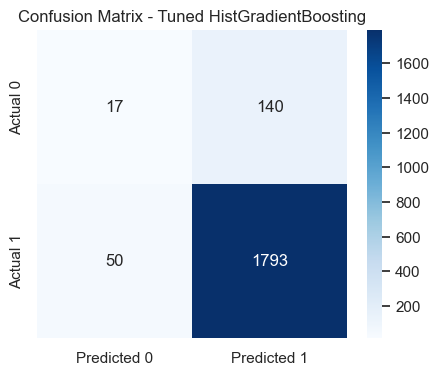

In [74]:
plt.figure(figsize=(5, 4))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - Tuned HistGradientBoosting")
plt.show()


## 11. How to Explain This to the Team

A simple explanation for your teammates:

1. We started from the cleaned dataset and defined the target.
2. We removed diagnosis/treatment proxy columns so the prediction task stays meaningful.
3. We split the data into training and test sets with stratification.
4. We computed **sample weights** using `compute_sample_weight("balanced")` to address class imbalance — class 0 (minority) receives a higher weight so the model stops ignoring it.
5. We built a preprocessing pipeline for HistGradientBoosting.
6. We measured the baseline model with cross-validation, passing sample weights via `fit_params`.
7. We tuned HistGradientBoosting with `GridSearchCV` using F1-score, passing sample weights to each fold.
8. We evaluated the best tuned model on the test set with Accuracy, Precision, Recall, and F1-score.

Why we added sample weights:
- Without balancing, HistGradientBoosting predicted class 1 for every respondent (`Recall_0 = 0.0`)
- Sample weights tell the model that misclassifying a class 0 respondent should be penalised more
- This forces the model to actually learn class 0 patterns instead of ignoring them

Why HistGradientBoosting is a strong candidate:
- it handles tabular data well
- it can learn nonlinear patterns
- it often performs better than a single tree or a simple linear model on structured datasets
- it gives a meaningful third comparison family next to Logistic Regression and Random Forest

## 12. Final Comparison Table for the Best Tuned Model

This table summarizes the final test-set metrics of the best HistGradientBoosting model using the best hyperparameters found during tuning.


In [75]:
final_comparison_table = pd.DataFrame([
    {
        "Model": "HistGradientBoosting",
        "learning_rate": grid_search.best_params_["model__learning_rate"],
        "max_depth": grid_search.best_params_["model__max_depth"],
        "max_iter": grid_search.best_params_["model__max_iter"],
        "min_samples_leaf": grid_search.best_params_["model__min_samples_leaf"],
        "n_estimators": None,
        "max_features": None,
        "Selection_Objective": "Best_CV_F1",
        "Selection_Score": round(grid_search.best_score_, 4),
        "Accuracy": round(accuracy, 4),
        "Balanced_Accuracy": round(balanced_acc, 4),
        "Precision_0": round(precision_0, 4),
        "Recall_0": round(recall_0, 4),
        "F1_0": round(f1_0, 4),
        "PR_AUC_0": round(pr_auc_0, 4),
        "Precision_1": round(precision_1, 4),
        "Recall_1": round(recall_1, 4),
        "F1_1": round(f1_1, 4),
        "PR_AUC_1": round(pr_auc_1, 4),
        "ROC_AUC_1": round(roc_auc_1, 4),
    }
])

final_comparison_table.to_csv("data/processed/histgradient_final_row.csv", index=False)
final_comparison_table


,Model,learning_rate,max_depth,max_iter,min_samples_leaf,n_estimators,max_features,Selection_Objective,Selection_Score,Accuracy,Balanced_Accuracy,Precision_0,Recall_0,F1_0,PR_AUC_0,Precision_1,Recall_1,F1_1,PR_AUC_1,ROC_AUC_1
0,HistGradientBoosting,0.1,7,200,20,None,None,Best_CV_F1,0.9508,0.905,0.5406,0.2537,0.1083,0.1518,0.1415,0.9276,0.9729,0.9497,0.9448,0.6271
